# 06 - Modelo: regresión con train 2024, val 2025 y test 2026

Este es el notebook del modelo. Entrenamos una **regresión** que aprende con los datos de 2024, elegimos sus parámetros con 2025 y al final la probamos una sola vez con 2026. Usa la columna `particion` de gold (ver `config.py`):

| Conjunto | Fechas | Para qué |
|---|---|---|
| `train` | todo 2024 | La regresión aprende |
| `val` | todo 2025 | Elegimos `alfa` y si usamos la combinación hora x tipo de día |
| `test` | 2026 (hasta donde haya datos) | Lo probamos una sola vez, al final |

Por qué un año entero para cada cosa está explicado en el README y en el notebook 00.

**El modelo.** Usamos **Ridge**, una regresión lineal con un castigo a los coeficientes grandes, sobre log(1 + pasajeros). Probamos dos versiones:

| Versión | Idea |
|---|---|
| `aditivo` | La hora y el tipo de día suman cada uno por su lado |
| `interacciones` | Además hay una columna por cada par hora x tipo de día, así cada tipo de día tiene su propia forma a lo largo del día |

Las dos versiones saben **qué tipo de día fue ayer** (EDA 3.3): hay una columna con el cambio (por ejemplo "domingo a hábil") y una copia del rezago de 1 día que vale 0 cuando ayer fue un tipo de día distinto a hoy. Además tienen tres cosas que salen de mirar dónde se equivocaban las reglas del 05 y la regresión en validación:

- **Rezagos que caen en un día raro.** Si un rezago cae en un feriado, en el 1° de mayo o en un paro, no dice nada de hoy. Ejemplo: el 2 de mayo, "ayer" es el 1° de mayo, que casi no tiene ómnibus. La mediana de 4 semanas aguanta una semana rara pero no dos: el 8 de mayo de 2025 miraba el 1° de mayo y el jueves de Turismo, y los miércoles de enero de 2025 miraban Navidad y Año Nuevo (los dos cayeron miércoles). En esos días la mediana daba la mitad de lo normal. Por eso armamos una **mediana limpia**, sin las semanas raras, y con ella cambiamos los rezagos raros. La regla `mediana_4sem` queda igual que en el 05.
- **Salto de clases.** `salto_clases_primaria` y `salto_clases_media` avisan cuando el estado de las clases cambió respecto de las 4 semanas que mira la mediana. Ejemplo: la primera semana de marzo la mediana mira semanas de vacaciones y se queda corta.
- **Paro.** `es_paro` marca los paros de transporte: el de todo el sistema del 31/07/2025 y los de una sola empresa (UCOT en mayo de 2024, UCOT y Coetc en abril de 2026), que se marcan solo en las líneas de esa empresa. En train solo está el de UCOT, que es medio día en unas pocas líneas, así que la regresión aprende muy poco de esta columna. El modelo final, entrenado con 2024 y 2025, ve también el paro general.

La lluvia entra como log(1 + mm), para que una tormenta no pese tanto más que una lluvia común.

**Regla a superar.** La mediana de las 4 semanas anteriores (`mediana_4sem`). También calculamos `perfil_historico` y `regla_por_tipo_dia` (el perfil en feriados y Turismo, y la mediana el resto de los días) con las mismas filas. Como en el 05 el perfil le ganó a la mediana, además medimos cuánto le gana la regresión a la mejor regla simple (sección 4.2).

**Cómo elegimos.** La regresión tiene dos "perillas" que hay que decidir antes de entrenar (**hiperparámetros**): `alfa` (qué tan fuerte es el castigo) y si usamos interacciones o no. Probamos unos pocos valores y nos quedamos con el que tiene menos error en val. Como elegimos mirando val, el error en val del ganador sale un poco más bajo de lo que va a ser en la realidad. El error de verdad lo vemos en test.

**Qué se guarda.** Los errores van a `resultados_modelos` con `etapa = 'modelo'` (validación) y `etapa = 'test'` (test).

## 0. Preparación

In [0]:
%run ./00_setup

# 00 - Preparar el proyecto

Este notebook deja todo listo para que los demás funcionen. Hace cuatro cosas:

1. Le dice a Python dónde está nuestro código (la carpeta `src/bondis`), para poder escribir `from bondis import ...`.
2. Crea en Databricks el lugar donde se guardan las tablas y los archivos (`bondis_stm.datos.raw`, definido en `config.py`).
3. Crea una carpeta para cada tipo de archivo (viajes, clima, etc.).
4. Muestra cómo dividimos los datos en train, val y test.

Se puede correr todas las veces que quieras. Si algo ya existe, no lo vuelve a crear ni lo borra.

No hace falta abrirlo a mano: los otros notebooks lo corren al principio con `%run ./00_setup`.

## 1. Encontrar nuestro código

Python solo puede importar código de las carpetas que conoce. Esta celda busca la carpeta del repositorio subiendo carpeta por carpeta hasta encontrar `src/bondis`, y la agrega a la lista de carpetas que Python conoce (`sys.path`).

## 2. Crear el catálogo, el esquema y el volume

Databricks ordena todo en tres niveles, como carpetas una dentro de otra:

- **Catálogo** (`bondis_stm`): la carpeta grande del proyecto.
- **Esquema** (`datos`): una subcarpeta donde van las tablas.
- **Volume** (`raw`): una carpeta para guardar archivos sueltos, como los ZIP y CSV que bajamos.


## 3. Crear una carpeta para cada tipo de archivo

| Carpeta | Qué va adentro |
|---|---|
| `viajes_zip/` | Los ZIP de viajes de cada mes, bajados a mano del portal de la Intendencia |
| `viajes/` | Los CSV de viajes, ya sacados de los ZIP |
| `clima/` | Lluvia y temperatura de cada hora |

El calendario (feriados, clases y paros) no tiene carpeta, porque está escrito a mano en `src/bondis/calendario.py`.

## 4. Revisar que todo esté bien

Muestra la versión de Spark y cuántos archivos hay en cada carpeta. Sirve para ver de un vistazo si falta subir algo.

## 5. Cómo dividimos los datos

Usamos las fechas para dividir, no el azar, porque queremos predecir el futuro con el pasado. Un año entero para cada cosa:

| Conjunto | Fechas | Para qué se usa |
|---|---|---|
| `train` | todo 2024 | El modelo aprende con estos datos |
| `val` | todo 2025 | Comparamos y elegimos los parámetros de la regresión |
| `test` | 2026 (lo que haya) | Probamos el modelo elegido una sola vez, al final |

La fecha de fin **no** está incluida. Por eso siempre se filtra con `fecha >= inicio` y `fecha < fin`.

`train_final` es train + val juntos. Cuando ya elegimos el modelo, lo volvemos a entrenar con 2024 y 2025 antes de probarlo en 2026.

In [0]:
import importlib
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

from bondis import metricas, modelos, variables

for _m in (metricas, modelos, variables):
    importlib.reload(_m)

spark.conf.set("spark.sql.session.timeZone", config.TIMEZONE)
plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

OBJ = modelos.OBJETIVO
REFERENCIA = "mediana_4sem"
COL_PARTICION = "particion"   # train 2024, val 2025, test 2026 (ver config.py)

## 1. Datos

Usamos solo las filas completas (con todos los rezagos y el clima). Si gold no tiene val en 2025 o le falta alguna columna nueva (como `es_paro`), el notebook avisa y hay que volver a correr el 03.

Test **no se baja todavía**. Se lee recién en la sección 9.

In [0]:
gold = variables.con_tipo_dia(spark.table(config.TABLE_GOLD)).where(F.col("fila_completa"))
primer_dia_val = gold.where(F.col(COL_PARTICION) == "val").agg(F.min("fecha")).first()[0]
assert primer_dia_val is not None and primer_dia_val.year == 2025, \
    "Gold no tiene val en 2025. Hay que volver a correr 03_features_gold."

leer, faltantes = modelos.columnas_a_leer(gold.columns)
if faltantes:
    print("Columnas opcionales que gold todavía no tiene (se siguen sin ellas):", faltantes)

base = gold.select(*leer, COL_PARTICION)
tamanos = variables.tamano_linea(gold.where(F.col(COL_PARTICION) == "train")).toPandas()


def bajar(particiones):
    """Pasa a pandas las filas de esos conjuntos y les agrega el tamaño de la línea."""
    df = (base.where(F.col(COL_PARTICION).isin(particiones)).drop(COL_PARTICION).toPandas()
          .merge(tamanos, on="linea", how="left")
          .fillna({"tamano_linea": "chica"}))
    return df


train_raw = bajar(["train"])
val_raw = bajar(["val"])

categorias = modelos.categorias_desde(train_raw)
train = modelos.preparar(train_raw, categorias)
val = modelos.preparar(val_raw, categorias)
del train_raw, val_raw   # para no ocupar memoria de más

# Cuántas filas tenían un rezago que caía en un día raro y se cambió por la mediana
for nombre, df in (("train", train), ("val", val)):
    print(f"{nombre}: rezagos cambiados por la mediana {df.attrs['rezagos_cambiados']}")

for nombre, df in (("train", train), ("val", val)):
    print(f"{nombre:<6} {len(df):>10,} filas, {df['fecha'].nunique()} días "
          f"({df['fecha'].min().date()} a {df['fecha'].max().date()}), {df['linea'].nunique()} líneas")

train: rezagos cambiados por la mediana {'mediana_limpia_distinta': 187138, 'pasajeros_lag_1d': 48912, 'pasajeros_lag_7d': 65184, 'pasajeros_lag_14d': 65184, 'pasajeros_lag_21d': 61920, 'pasajeros_lag_28d': 68352}
val: rezagos cambiados por la mediana {'mediana_limpia_distinta': 230822, 'pasajeros_lag_1d': 55488, 'pasajeros_lag_7d': 91392, 'pasajeros_lag_14d': 94656, 'pasajeros_lag_21d': 91392, 'pasajeros_lag_28d': 94656}
train   1,100,208 filas, 338 días (2024-01-29 a 2024-12-31), 136 líneas
val     1,191,360 filas, 365 días (2025-01-01 a 2025-12-31), 136 líneas


## 2. Reglas para comparar

Las mismas reglas simples del 05, ahora calculadas con train = 2024 y medidas en val = 2025:
- `mediana_4sem`: la mediana de las 4 semanas anteriores (la que hay que superar).
- `perfil_historico`: el promedio de 2024 para la misma línea, hora y tipo de día.
- `regla_por_tipo_dia`: el perfil en feriados y Turismo, y la mediana el resto de los días. Sale de lo que vimos en el 05, sección 3.1.

In [0]:
PRED = {}   # para cada modelo, en qué columna de val está su predicción
for nombre, valores in modelos.referencias(train, val).items():
    val[f"pred_{nombre}"] = valores
    PRED[nombre] = f"pred_{nombre}"
    print(f"{nombre:<20} MAE val {np.abs(valores - val[OBJ]).mean():6.2f}")

mediana_4sem         MAE val  39.73
perfil_historico     MAE val  37.56
regla_por_tipo_dia   MAE val  34.82


## 3. Regresión Ridge

Probamos dos versiones (sin y con la combinación hora x tipo de día) y cinco valores de `alfa` (qué tan fuerte se castigan los coeficientes grandes). Nos quedamos con la que tenga menos MAE en val.

Train tiene todo 2024, con diciembre incluido, así que las columnas de fin de año (`es_vispera_navidad`, `es_fin_de_anio`, `es_semana_fiestas`) tienen días marcados en train y la regresión les puede dar un peso.

In [0]:
# Por qué los alfas son tan grandes: ver sección 6.2
ALFAS = [1, 1_000, 10_000, 100_000, 1_000_000]

CANDIDATOS = {}   # para cada modelo: (tipo de modelo, sus parámetros)
for interacciones, etiqueta in ((False, "aditivo"), (True, "interacciones")):
    for alfa in ALFAS:
        CANDIDATOS[f"lineal_{etiqueta}_a{alfa}"] = ("lineal", {"interacciones": interacciones, "alfa": alfa})

ajustados = {}


def entrenar(candidatos):
    for nombre, (familia, params) in candidatos.items():
        modelo = modelos.crear_modelo(train.columns, familia, **params)
        pred, seg = modelos.ajustar_y_predecir(modelo, train, val)
        val[f"pred_{nombre}"] = pred
        PRED[nombre] = f"pred_{nombre}"
        ajustados[nombre] = modelo
        print(f"{nombre:<32} {seg:6.1f} s   MAE val {np.abs(pred - val[OBJ]).mean():6.2f}")


entrenar(CANDIDATOS)

lineal_aditivo_a1                   3.8 s   MAE val  31.03
lineal_aditivo_a1000                2.4 s   MAE val  30.97
lineal_aditivo_a10000               2.1 s   MAE val  31.25
lineal_aditivo_a100000              1.9 s   MAE val  37.37
lineal_aditivo_a1000000             2.0 s   MAE val 104.95
lineal_interacciones_a1             5.0 s   MAE val  30.86
lineal_interacciones_a1000          4.6 s   MAE val  30.72
lineal_interacciones_a10000         3.6 s   MAE val  30.99
lineal_interacciones_a100000        2.9 s   MAE val  37.07
lineal_interacciones_a1000000       2.3 s   MAE val 104.63


## 4. Resultados en validación

Igual que en el 05 (ahí está explicado el bootstrap por semanas). Todos los modelos usan las mismas semanas sorteadas, por eso el intervalo de la **mejora** es el que dice si un modelo le gana de verdad a la mediana de 4 semanas.

In [0]:
est = modelos.estadisticos_por_dia(val, OBJ, PRED, grupos=["tipo_dia", "tamano_linea"])

globales = metricas.agregar_mejora(metricas.metricas(est), REFERENCIA)
intervalos = metricas.bootstrap_dias(est, REFERENCIA, n_rep=1000, seed=config.SEED, bloque=7)
globales = globales.merge(intervalos, on="modelo").sort_values("mae").reset_index(drop=True)


def fmt_intervalo(v, inf, sup, dec=1, pct=False):
    f = (lambda x: f"{100 * x:.{dec}f} %") if pct else (lambda x: f"{x:,.{dec}f}")
    return f"{f(v)} [{f(inf)} a {f(sup)}]"


def tabla_linda(g):
    return pd.DataFrame({
        "modelo": g["modelo"],
        "MAE [IC 95 %]": [fmt_intervalo(*x) for x in g[["mae", "mae_inf", "mae_sup"]].to_numpy()],
        "RMSE": g["rmse"].round(1),
        "R²": g["r2"].round(3),
        "WAPE": (100 * g["wape"]).round(1).astype(str) + " %",
        "sesgo": g["sesgo"].round(1),
        "mejora [IC 95 %]": [fmt_intervalo(*x, pct=True)
                             for x in g[["mejora_mae", "mejora_mae_inf", "mejora_mae_sup"]].to_numpy()],
    })


print(tabla_linda(globales).to_string(index=False))

                       modelo         MAE [IC 95 %]  RMSE    R²   WAPE  sesgo               mejora [IC 95 %]
   lineal_interacciones_a1000    30.7 [28.7 a 33.3]  65.9 0.970 12.3 %   -3.5       22.7 % [15.7 % a 30.1 %]
      lineal_interacciones_a1    30.9 [28.7 a 33.7]  66.7 0.969 12.3 %   -2.7       22.3 % [15.2 % a 29.9 %]
         lineal_aditivo_a1000    31.0 [28.9 a 33.4]  66.1 0.970 12.4 %   -4.6       22.0 % [15.1 % a 29.4 %]
  lineal_interacciones_a10000    31.0 [29.1 a 33.2]  65.9 0.970 12.4 %   -5.9       22.0 % [14.9 % a 29.5 %]
            lineal_aditivo_a1    31.0 [28.9 a 33.6]  66.3 0.969 12.4 %   -4.3       21.9 % [14.7 % a 29.3 %]
        lineal_aditivo_a10000    31.2 [29.4 a 33.5]  66.5 0.969 12.5 %   -6.5       21.3 % [14.2 % a 29.0 %]
           regla_por_tipo_dia    34.8 [31.6 a 38.5]  77.6 0.958 13.9 %   -1.3        12.4 % [5.8 % a 20.1 %]
 lineal_interacciones_a100000    37.1 [35.4 a 38.9]  81.1 0.954 14.8 %  -20.1        6.7 % [-4.3 % a 18.1 %]
       lineal_aditi

**Cómo leer la tabla.**
- Está ordenada de menor a mayor MAE. La **mejora** es 1 menos el MAE del modelo dividido el MAE de `mediana_4sem`. Un 0,10 es un 10 % menos de error.
- Si el intervalo de la mejora incluye el 0, no podemos decir que el modelo le gane a la mediana.
- Si el RMSE es mucho más grande que el MAE, hay pocos errores muy grandes (feriados, elecciones).
- El sesgo dice hacia dónde se equivoca: positivo, predice de más. Negativo, predice de menos. Los modelos con log suelen quedar con sesgo negativo, porque al deshacer el logaritmo la predicción se parece más a una mediana que a un promedio, y en estos datos la mediana es más baja que el promedio.

### 4.1 El mejor de cada versión

Miramos la mejor regresión sin interacciones y la mejor con interacciones, para ver cuánto aporta la combinación hora x tipo de día.

In [0]:
familia_de = {n: "lineal_" + n.split("_")[1] for n in CANDIDATOS}   # lineal_aditivo o lineal_interacciones
cand = globales[globales["modelo"].isin(CANDIDATOS)].copy()
cand["familia"] = cand["modelo"].map(familia_de)
mejores = cand.loc[cand.groupby("familia")["mae"].idxmin()].sort_values("mae")
print(mejores[["familia", "modelo", "mae", "rmse", "sesgo", "mejora_mae", "mejora_mae_inf", "mejora_mae_sup"]]
      .round(3).to_string(index=False))

MEJOR = cand.sort_values("mae")["modelo"].iloc[0]
fila = globales.set_index("modelo").loc[MEJOR]
print(f"\nRegresión elegida en validación: {MEJOR}")
print(f"  MAE {fila['mae']:.1f}, mejora sobre {REFERENCIA}: {100 * fila['mejora_mae']:.1f} % "
      f"[{100 * fila['mejora_mae_inf']:.1f} % a {100 * fila['mejora_mae_sup']:.1f} %]")
if fila["mejora_mae_inf"] <= 0:
    print("  El intervalo de la mejora incluye el 0. En validación no se puede decir que le gane a la mediana de 4 semanas.")

             familia                     modelo    mae   rmse  sesgo  mejora_mae  mejora_mae_inf  mejora_mae_sup
lineal_interacciones lineal_interacciones_a1000 30.724 65.902 -3.509       0.227           0.157           0.301
      lineal_aditivo       lineal_aditivo_a1000 30.970 66.119 -4.604       0.220           0.151           0.294

Regresión elegida en validación: lineal_interacciones_a1000
  MAE 30.7, mejora sobre mediana_4sem: 22.7 % [15.7 % a 30.1 %]


### 4.2 Contra la mejor regla simple

La mediana no es la mejor regla simple (ver 05). Para no exagerar lo que aporta la regresión, medimos también cuánto le gana a la mejor de las tres reglas, con el mismo bootstrap por semanas.

In [0]:
REGLAS = ["mediana_4sem", "perfil_historico", "regla_por_tipo_dia"]
MEJOR_REGLA = globales[globales["modelo"].isin(REGLAS)].sort_values("mae")["modelo"].iloc[0]
sub = est[est["modelo"].isin([*CANDIDATOS, MEJOR_REGLA])]
contra_regla = (metricas.agregar_mejora(metricas.metricas(sub), MEJOR_REGLA)[["modelo", "mae", "mejora_mae"]]
                .merge(metricas.bootstrap_dias(sub, MEJOR_REGLA, n_rep=1000, seed=config.SEED, bloque=7)
                       [["modelo", "mejora_mae_inf", "mejora_mae_sup"]], on="modelo")
                .sort_values("mae").reset_index(drop=True))
print(f"Mejor regla simple en validación: {MEJOR_REGLA}\n")
print(contra_regla[contra_regla["modelo"] != MEJOR_REGLA].round(3).to_string(index=False))

Mejor regla simple en validación: regla_por_tipo_dia

                       modelo     mae  mejora_mae  mejora_mae_inf  mejora_mae_sup
   lineal_interacciones_a1000  30.724       0.118           0.065           0.173
      lineal_interacciones_a1  30.863       0.114           0.056           0.172
         lineal_aditivo_a1000  30.970       0.111           0.058           0.164
  lineal_interacciones_a10000  30.988       0.110           0.059           0.161
            lineal_aditivo_a1  31.027       0.109           0.056           0.164
        lineal_aditivo_a10000  31.250       0.103           0.051           0.155
 lineal_interacciones_a100000  37.069      -0.065          -0.151           0.027
       lineal_aditivo_a100000  37.374      -0.073          -0.163           0.020
lineal_interacciones_a1000000 104.627      -2.005          -2.370          -1.637
      lineal_aditivo_a1000000 104.951      -2.014          -2.380          -1.645


## 5. ¿Dónde mejora y dónde no?

La mediana de 4 semanas acierta casi siempre, así que un modelo solo puede ganar en los días que no se parecen a las semanas anteriores. Comparamos la mediana, las otras reglas, la mejor de cada versión y la elegida, separando por tipo de día.

In [0]:
MOSTRAR = [REFERENCIA, "perfil_historico", "regla_por_tipo_dia", *mejores["modelo"]]
MOSTRAR = list(dict.fromkeys(MOSTRAR))
orden = [m for m in globales["modelo"] if m in MOSTRAR]

por_tipo = metricas.agregar_mejora(metricas.metricas(est, por=["tipo_dia"]), REFERENCIA, por=["tipo_dia"])
dias_tipo = est.drop_duplicates(["fecha", "tipo_dia"]).groupby("tipo_dia")["fecha"].nunique().rename("días")
tipos = [t for t in variables.TIPOS_DIA if t in dias_tipo.index]

print("MAE por tipo de día (pasajeros por hora):")
t = por_tipo.pivot(index="modelo", columns="tipo_dia", values="mae").loc[orden, tipos].round(1)
print(pd.concat([dias_tipo[tipos].to_frame().T, t]).to_string(), "\n")

print("Sesgo por tipo de día (> 0: se pasa):")
print(por_tipo.pivot(index="modelo", columns="tipo_dia", values="sesgo").loc[orden, tipos].round(1).to_string())

MAE por tipo de día (pasajeros por hora):
tipo_dia                    hábil  sábado  domingo  turismo  feriado
días                        249.0    50.0     51.0      7.0      8.0
lineal_interacciones_a1000   33.3    24.0     21.4     51.9     32.7
lineal_aditivo_a1000         33.7    23.8     21.7     50.6     32.8
regla_por_tipo_dia           38.5    25.2     21.6     49.7     51.7
perfil_historico             42.0    26.1     23.2     49.7     51.7
mediana_4sem                 38.5    25.2     21.6    122.9    211.6 

Sesgo por tipo de día (> 0: se pasa):
tipo_dia                    hábil  sábado  domingo  turismo  feriado
modelo                                                              
lineal_interacciones_a1000   -0.2    -9.9     -7.6    -28.4    -18.5
lineal_aditivo_a1000         -2.4    -9.3     -8.9    -13.5     -8.4
regla_por_tipo_dia           -1.9    -0.3     -1.7      3.4      6.5
perfil_historico             11.2     8.3      7.0      3.4      6.5
mediana_4sem         

### 5.1 Por tamaño de línea

El MAE lo deciden las líneas grandes. El WAPE, como es un porcentaje, sirve para comparar grupos de distinto tamaño.

In [0]:
por_tam = metricas.metricas(est, por=["tamano_linea"])
grupos_tam = [g for g in ["grande", "mediana", "chica"] if g in set(por_tam["tamano_linea"])]
for col, titulo in (("mae", "MAE"), ("wape", "WAPE")):
    t = por_tam.pivot(index="modelo", columns="tamano_linea", values=col).loc[orden, grupos_tam]
    print(f"{titulo} por tamaño de línea:")
    print((t * 100).round(1).astype(str).add(" %").to_string() if col == "wape" else t.round(1).to_string(), "\n")

MAE por tamaño de línea:
tamano_linea                grande  mediana  chica
modelo                                            
lineal_interacciones_a1000    75.7     50.8   13.3
lineal_aditivo_a1000          76.2     51.3   13.4
regla_por_tipo_dia            85.8     59.0   14.5
perfil_historico              93.0     63.5   15.6
mediana_4sem                  97.8     68.0   16.4 

WAPE por tamaño de línea:
tamano_linea                grande mediana   chica
modelo                                            
lineal_interacciones_a1000  10.7 %  11.5 %  17.2 %
lineal_aditivo_a1000        10.8 %  11.6 %  17.3 %
regla_por_tipo_dia          12.1 %  13.4 %  18.8 %
perfil_historico            13.2 %  14.4 %  20.3 %
mediana_4sem                13.8 %  15.4 %  21.2 % 



### 5.2 Día por día

El MAE de cada día de validación para la mediana de 4 semanas y para el modelo elegido. Las líneas grises punteadas son días especiales y las rojas son días en que empiezan o terminan las clases.

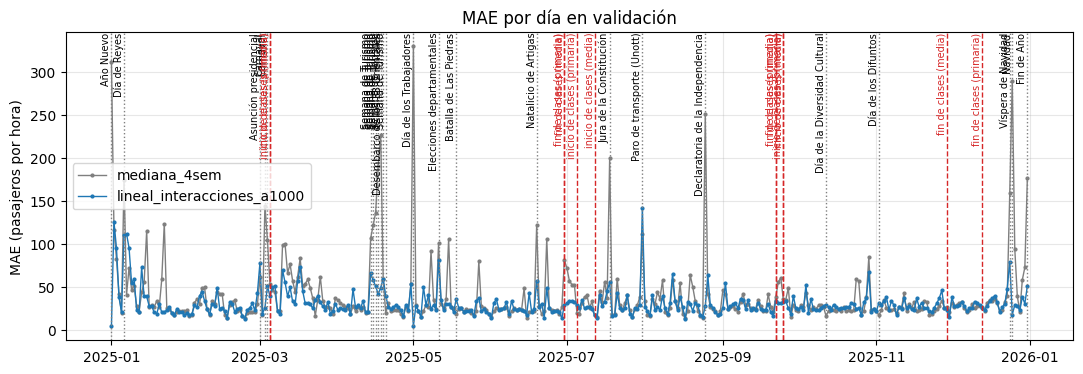

Los 10 días con más error de lineal_interacciones_a1000:
     fecha tipo_dia        nombre_dia_especial   mae  sesgo  mae_referencia
2025-07-31    hábil Paro de transporte (Unott) 142.3  140.0           111.6
2025-01-02    hábil                       None 125.6  125.0           116.7
2025-01-07    hábil                       None 111.7  110.0            40.7
2025-01-06    hábil               Día de Reyes 109.9  104.9           174.0
2025-01-08    hábil                       None  95.2   93.8            72.1
2025-01-03    hábil                       None  95.1   93.8            82.6
2025-05-11  domingo Elecciones departamentales  81.3  -47.6           100.7
2025-12-24    hábil         Víspera de Navidad  79.4  -41.2           158.8
2025-03-01  feriado      Asunción presidencial  77.5  -76.8            61.1
2025-03-17    hábil                       None  73.1  -56.8            83.1


In [0]:
info_dias = (val[["fecha", "tipo_dia", "nombre_dia_especial", "clases_primaria", "clases_media"]]
             .drop_duplicates("fecha"))
info_dias = info_dias.assign(tipo_dia=info_dias["tipo_dia"].astype(str))

diario = metricas.metricas(est.groupby(["modelo", "fecha"], as_index=False)[metricas.ESTADISTICOS].sum(), por=["fecha"])
fig, ax = plt.subplots()
for m, color in ((REFERENCIA, "tab:gray"), (MEJOR, "tab:blue")):
    s = diario[diario["modelo"] == m].sort_values("fecha")
    ax.plot(s["fecha"], s["mae"], marker=".", ms=4, lw=1, label=m, color=color)
tope = ax.get_ylim()[1]
for _, d in info_dias.dropna(subset=["nombre_dia_especial"]).iterrows():
    ax.axvline(d["fecha"], color="gray", ls=":", lw=1)
    ax.text(d["fecha"], tope, d["nombre_dia_especial"], rotation=90, va="top", ha="right", fontsize=7)

cal = info_dias.sort_values("fecha").set_index("fecha")[["clases_primaria", "clases_media"]]
for nivel in ("primaria", "media"):
    c = cal[f"clases_{nivel}"].astype(int).diff()
    for f, v in c[c != 0].dropna().items():
        etiqueta = f"{'inicio' if v > 0 else 'fin'} de clases ({nivel})"
        ax.axvline(f, color="tab:red", ls="--", lw=1)
        ax.text(f, tope, etiqueta, rotation=90, va="top", ha="right", fontsize=7, color="tab:red")

ax.set(title="MAE por día en validación", ylabel="MAE (pasajeros por hora)")
ax.legend(loc="center left")
plt.show()

peores = (diario[diario["modelo"] == MEJOR].nlargest(10, "mae")
          .merge(info_dias, on="fecha")[["fecha", "tipo_dia", "nombre_dia_especial", "mae", "sesgo"]])
ref_dia = diario[diario["modelo"] == REFERENCIA].set_index("fecha")["mae"].rename("mae_referencia")
peores = peores.merge(ref_dia, left_on="fecha", right_index=True)
print(f"Los 10 días con más error de {MEJOR}:")
print(peores.round(1).to_string(index=False))

**Qué vimos.** Con la mediana limpia ya no aparecen el 8 de mayo ni los miércoles de enero. Los días que quedan son de dos tipos:
- **El paro del 31/07** (el modelo predice 140 pasajeros por hora de más). En 2024 no hubo ningún paro de todo el sistema (solo uno de UCOT), así que la regresión no tiene de dónde aprenderlo. El modelo final, entrenado con 2025, sí lo ve una vez.
- **La primera semana de enero** (del 2 al 8, todos con sesgo positivo). La mediana limpia saca Navidad y Año Nuevo y se queda con semanas normales de diciembre, pero en enero viaja mucha menos gente por las vacaciones. Ninguna variable le dice al modelo "esto es enero". Antes la mediana rota le pegaba de casualidad, porque los feriados la bajaban.

Los demás (Reyes, las elecciones, la víspera de Navidad, la asunción presidencial, el 17 de marzo) son días únicos que en train aparecen una sola vez o ninguna.

### 5.3 Mes por mes

Con un año entero en val podemos ver en qué épocas la regresión le gana a la mediana y en cuáles no. Lo esperable es que gane en los meses con más días distintos a las semanas anteriores: diciembre (fiestas y fin de clases), marzo (comienzo de clases) y los meses con feriados largos como Carnaval y Turismo.

MAE por mes:
modelo  lineal_interacciones_a1000  lineal_aditivo_a1000  regla_por_tipo_dia  perfil_historico  mediana_4sem
mes                                                                                                         
1                             40.6                  40.3                48.5              71.1          56.1
2                             26.7                  27.5                27.6              47.2          27.6
3                             38.0                  38.2                47.6              32.8          52.6
4                             32.8                  32.9                31.2              34.7          48.3
5                             27.6                  27.8                35.0              32.1          43.2
6                             26.1                  26.4                31.1              35.0          31.1
7                             32.1                  32.2                36.3              35.3          41.8
8     

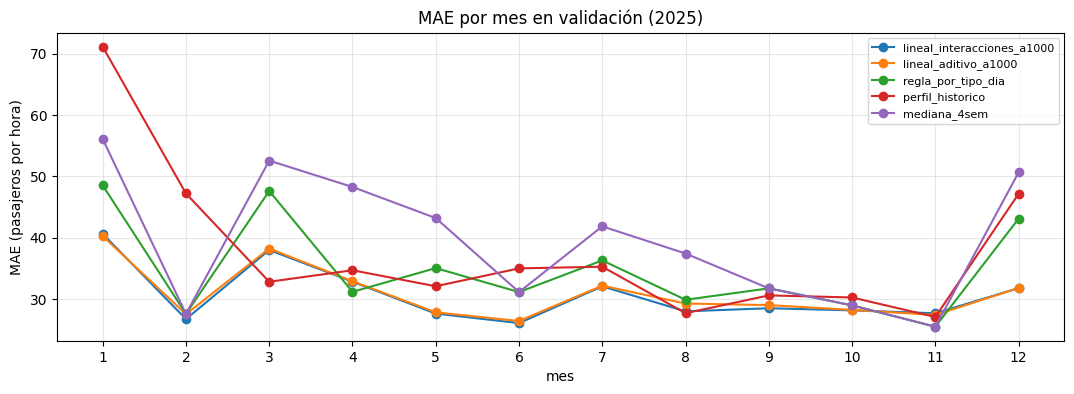

In [0]:
est_mes = est.assign(mes=est["fecha"].dt.month)
por_mes = metricas.metricas(est_mes, por=["mes"])
t = por_mes.pivot(index="mes", columns="modelo", values="mae")[orden]
print("MAE por mes:")
print(t.round(1).to_string())

fig, ax = plt.subplots()
for m in orden:
    ax.plot(t.index, t[m], marker="o", label=m)
ax.set(title="MAE por mes en validación (2025)", xlabel="mes", ylabel="MAE (pasajeros por hora)", xticks=range(1, 13))
ax.legend(fontsize=8)
plt.show()

## 6. Error en train y en validación: ¿subajuste o sobreajuste?

Hay dos formas de que un modelo salga mal:

- **Subajuste**: el modelo es demasiado simple y no aprende ni siquiera con los datos que vio. Es como estudiar solo el índice del libro. El error es **alto en train y también alto en validación**.
- **Sobreajuste**: el modelo se aprende de memoria los detalles de train, incluso los que fueron casualidad, y después no le va bien con datos nuevos. Es como aprenderse las respuestas del práctico sin entender: en el práctico te va perfecto y en el examen no. El error en train es **mucho más bajo** que en validación.

En nuestro problema hay una trampa: validación no es una parte al azar de train, es otro año (2025). Entonces el error en validación puede ser distinto al de train solo porque cambió algo de un año al otro (más o menos pasajeros, líneas que cambiaron), no porque el modelo esté sobreajustado.

Para separar las dos cosas usamos la mediana de 4 semanas como "termómetro". Es una aproximación, porque supone que el cambio de año afecta igual al modelo y a la mediana. Esa regla no aprende nada, así que no puede sobreajustar. Si su error cambia entre train y validación, es solo por el cambio de año. Entonces calculamos el **exceso**:

$$\text{exceso} = \frac{\text{MAE val del modelo} \,/\, \text{MAE train del modelo}}{\text{MAE val de la mediana} \,/\, \text{MAE train de la mediana}}$$

- Exceso cerca de 1: la diferencia entre train y validación se explica por el cambio de año. No hay sobreajuste.
- Exceso bastante mayor que 1: el modelo empeora en validación más que la mediana. Hay sobreajuste.

### 6.1 Error en train y en validación de cada modelo

El MAE de train se mide sobre una muestra de 200 mil filas, para que sea más rápido.

In [0]:
N_TRAIN_CURVAS = 200_000
sub_train = train.sample(n=min(N_TRAIN_CURVAS, len(train)), random_state=config.SEED)
ref_tr = modelos.mae(sub_train[OBJ], sub_train[modelos.REFERENCIA])
ref_va = modelos.mae(val[OBJ], val[modelos.REFERENCIA])
brecha_ref = ref_va / ref_tr
print(f"{REFERENCIA}: MAE train {ref_tr:.2f}, MAE val {ref_va:.2f}, cociente val/train {brecha_ref:.2f}\n")

diag = modelos.error_train_val(ajustados, list(CANDIDATOS), train, val, n_train=N_TRAIN_CURVAS, semilla=config.SEED)
diag["brecha"] = diag["mae_val"] - diag["mae_train"]
diag["val/train"] = diag["mae_val"] / diag["mae_train"]
diag["exceso"] = diag["val/train"] / brecha_ref
diag["mejora_en_train"] = 1 - diag["mae_train"] / ref_tr
print(diag.sort_values("mae_val").round(3).to_string(index=False))

mediana_4sem: MAE train 38.25, MAE val 39.73, cociente val/train 1.04

                       modelo  mae_train  mae_val  brecha  val/train  exceso  mejora_en_train
   lineal_interacciones_a1000     30.518   30.724   0.206      1.007   0.969            0.202
      lineal_interacciones_a1     30.477   30.863   0.386      1.013   0.975            0.203
         lineal_aditivo_a1000     30.827   30.970   0.143      1.005   0.967            0.194
  lineal_interacciones_a10000     31.394   30.988  -0.406      0.987   0.950            0.179
            lineal_aditivo_a1     30.745   31.027   0.282      1.009   0.972            0.196
        lineal_aditivo_a10000     31.717   31.250  -0.467      0.985   0.949            0.171
 lineal_interacciones_a100000     39.007   37.069  -1.937      0.950   0.915           -0.020
       lineal_aditivo_a100000     39.332   37.374  -1.958      0.950   0.915           -0.028
lineal_interacciones_a1000000    111.286  104.627  -6.660      0.940   0.905       

**Cómo leer la tabla.** `mejora_en_train` dice cuánto le gana el modelo a la mediana en los datos que vio. Si es baja, el modelo no logra aprender ni siquiera train (subajuste, o simplemente no hay mucho más para aprender). Un `exceso` bastante mayor que 1 indica sobreajuste. Si el `exceso` está cerca de 1 y la mejora en train se parece a la mejora en validación, el modelo funciona igual en los dos años.

### 6.2 El error según `alfa`

`alfa` es el castigo a los coeficientes grandes. Con `alfa` muy grande el modelo queda demasiado rígido y no aprende (subajuste). Con `alfa` muy chico es casi una regresión lineal común y podría sobreajustar, aunque con tantas filas y pocas columnas casi no pasa.

Los `alfa` parecen enormes por una cuestión de escala. Ridge compara el castigo contra la suma de los errores de **todas** las filas, que son más o menos un millón. Por eso un `alfa` de 0,1 o de 100 es chiquito al lado de esa suma y da prácticamente el mismo modelo. Para que se note algo hay que ir a valores de miles o millones. Si la curva sale plana en los valores chicos y sube recién en los grandes, quiere decir que el castigo no hacía falta.

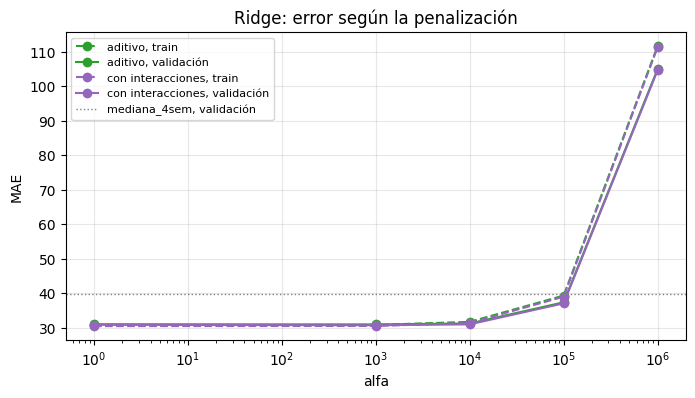

         variante    alfa  mae_train  mae_val  brecha  exceso
          aditivo       1     30.745   31.027   0.282   0.972
          aditivo    1000     30.827   30.970   0.143   0.967
          aditivo   10000     31.717   31.250  -0.467   0.949
          aditivo  100000     39.332   37.374  -1.958   0.915
          aditivo 1000000    111.625  104.951  -6.674   0.905
con interacciones       1     30.477   30.863   0.386   0.975
con interacciones    1000     30.518   30.724   0.206   0.969
con interacciones   10000     31.394   30.988  -0.406   0.950
con interacciones  100000     39.007   37.069  -1.937   0.915
con interacciones 1000000    111.286  104.627  -6.660   0.905


In [0]:
lin = diag[diag["modelo"].isin([n for n, c in CANDIDATOS.items() if c[0] == "lineal"])].copy()
lin["alfa"] = lin["modelo"].map(lambda n: CANDIDATOS[n][1]["alfa"])
lin["variante"] = lin["modelo"].map(lambda n: "con interacciones" if CANDIDATOS[n][1]["interacciones"] else "aditivo")

fig, ax = plt.subplots(figsize=(8, 4))
for (variante, g), color in zip(lin.groupby("variante"), ("tab:green", "tab:purple")):
    g = g.sort_values("alfa")
    ax.plot(g["alfa"], g["mae_train"], ls="--", marker="o", color=color, label=f"{variante}, train")
    ax.plot(g["alfa"], g["mae_val"], ls="-", marker="o", color=color, label=f"{variante}, validación")
ax.axhline(ref_va, color="gray", ls=":", lw=1, label=f"{REFERENCIA}, validación")
ax.set(xscale="log", xlabel="alfa", ylabel="MAE", title="Ridge: error según la penalización")
ax.legend(fontsize=8)
plt.show()
print(lin.sort_values(["variante", "alfa"])[["variante", "alfa", "mae_train", "mae_val", "brecha", "exceso"]].round(3).to_string(index=False))

### 6.3 Curva de aprendizaje: ¿más datos ayudarían?

Volvemos a entrenar el modelo elegido con una parte cada vez más grande de los **días** de train (10 %, 25 %, 50 %, 75 % y 100 %). Se sortean días enteros, no filas sueltas. Cada vez medimos el error en esos mismos días y en validación.

- Si las dos curvas se juntan y quedan **planas y altas**: más datos no ayudan. El problema es el modelo (subajuste) o que hay cosas que no se pueden predecir.
- Si hay una **distancia entre las curvas que se achica** al agregar datos: más datos ayudarían, y el modelo hoy está un poco sobreajustado.
- Con pocos días, train no tiene todos los tipos de día. Por eso, del lado izquierdo del gráfico la distancia mezcla sobreajuste con falta de ejemplos.

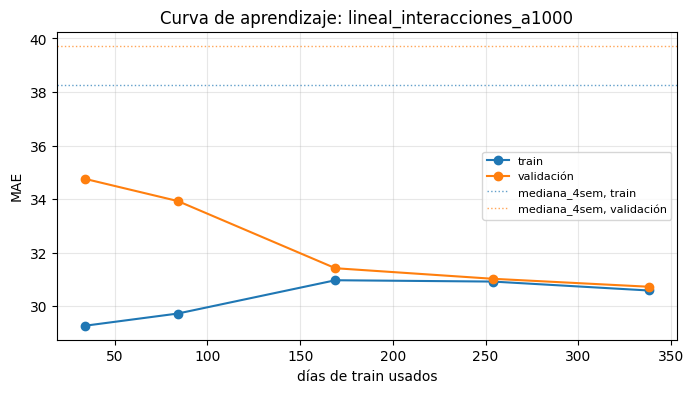

 fraccion  dias   filas  mae_train  mae_val  segundos
     0.10    34  110688     29.267   34.754     0.549
     0.25    84  273312     29.722   33.926     0.820
     0.50   169  550080     30.967   31.416     2.246
     0.75   254  826896     30.917   31.021     3.277
     1.00   338 1100208     30.584   30.724     5.241


In [0]:
familia_m, params_m = CANDIDATOS[MEJOR]
curva_ap = modelos.curva_aprendizaje(
    lambda: modelos.crear_modelo(train.columns, familia_m, **params_m),
    train, val, fracciones=(0.1, 0.25, 0.5, 0.75, 1.0), semilla=config.SEED)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curva_ap["dias"], curva_ap["mae_train"], marker="o", color="tab:blue", label="train")
ax.plot(curva_ap["dias"], curva_ap["mae_val"], marker="o", color="tab:orange", label="validación")
ax.axhline(ref_tr, color="tab:blue", ls=":", lw=1, alpha=0.7, label=f"{REFERENCIA}, train")
ax.axhline(ref_va, color="tab:orange", ls=":", lw=1, alpha=0.7, label=f"{REFERENCIA}, validación")
ax.set(xlabel="días de train usados", ylabel="MAE", title=f"Curva de aprendizaje: {MEJOR}")
ax.legend(fontsize=8)
plt.show()
print(curva_ap.round(3).to_string(index=False))

**Qué vimos en la sección 6.**
- No hay sobreajuste. El error de train y el de validación son casi iguales para todas las regresiones, y el `exceso` da cerca de 1. Con un millón de filas y unas pocas columnas no hay de dónde sobreajustar.
- El castigo no hace falta. Con `alfa` de 1 a 1000 el error es el mismo, y desde 10.000 sube en train y en validación a la vez, que es subajuste.
- La curva de aprendizaje se aplana y las dos curvas quedan juntas. Más días de 2024 no ayudarían. Lo que limita al modelo es lo que sabe (las variables), no la cantidad de datos.
- Train tiene un solo año, así que de cada día especial (Navidad, Carnaval, Turismo) hay un solo ejemplo. Al volver a entrenar con train + val para test, el modelo ve dos de cada uno.

## 7. ¿Qué variables usa más el modelo?

Usamos la **importancia por permutación**. La idea es simple: tomamos una muestra de validación y **mezclamos al azar** los valores de un grupo de variables, como si barajáramos esa columna. Así esa variable deja de tener sentido. Después medimos cuánto sube el MAE:
- Si sube mucho, el modelo dependía mucho de esa variable.
- Si casi no sube, el modelo no la usaba mucho.

Las variables se mezclan en grupos porque varias dicen casi lo mismo (los rezagos, el promedio y la mediana de 4 semanas). Si mezcláramos una sola, el modelo usaría las otras y parecería que no importa.

Dos cuidados al leer el resultado. Al mezclar los rezagos, a una línea chica le tocan los pasajeros de una grande y la predicción se rompe por completo, por eso ese grupo da muchísimo. Y la regresión no usa la línea (solo `tipo_linea`), porque el nivel de cada línea ya viene en los rezagos, así que ese grupo da casi 0. Eso no quiere decir que la línea no importe.

Es una medida aproximada. No dice que una variable **cause** más pasajeros. Y si un grupo da importancia baja, puede ser que no sirva o que otro grupo diga lo mismo.

MAE de lineal_interacciones_a1000 en la muestra sin desordenar: 30.49

                     grupo  mae_permutado  aumento_mae  aumento_pct
      rezagos de pasajeros        339.620      309.127       10.138
  tipo de día (hoy y ayer)         45.335       14.842        0.487
                      hora         38.485        7.992        0.262
feriados y días especiales         37.121        6.627        0.217
                fin de año         33.029        2.536        0.083
                     clima         33.015        2.522        0.083
                    clases         32.017        1.524        0.050
                     línea         30.683        0.190        0.006


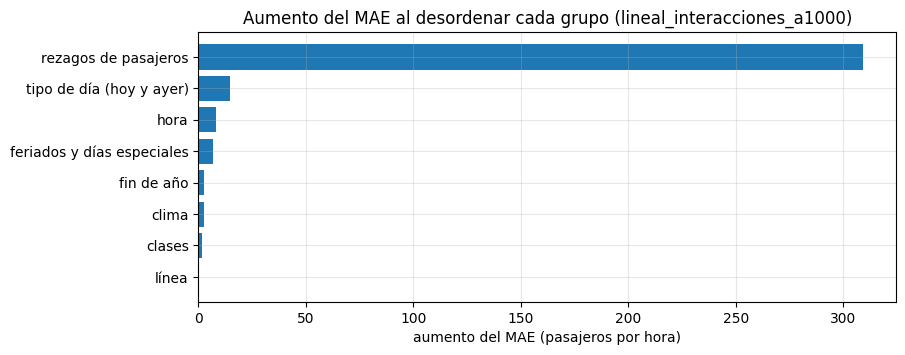

In [0]:
muestra = val.sample(n=min(100_000, len(val)), random_state=config.SEED)
imp = modelos.importancia_por_grupos(ajustados[MEJOR], muestra, modelos.grupos_de_variables(val.columns),
                                     n_rep=3, seed=config.SEED)
print(f"MAE de {MEJOR} en la muestra sin desordenar: {imp.attrs['mae_base']:.2f}\n")
print(imp[["grupo", "mae_permutado", "aumento_mae", "aumento_pct"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(imp["grupo"][::-1], imp["aumento_mae"][::-1], color="tab:blue")
ax.set(title=f"Aumento del MAE al desordenar cada grupo ({MEJOR})", xlabel="aumento del MAE (pasajeros por hora)")
plt.show()

### 7.1 Los coeficientes de la regresión

Antes de entrenar, cada columna numérica se divide por su desvío (`StandardScaler`), también las de sí o no. Por eso el coeficiente que guarda Ridge es "por cada desvío" (`coef_estandarizado`). Sirve para ver qué variable pesa más, pero no dice cuánto cambian los pasajeros. Para eso lo pasamos a "por cada unidad" (`coef_por_unidad`), dividiendo por el desvío de la columna:

- En las de sí o no, `cambio_pct` = exp(coef_por_unidad) - 1 es más o menos cuánto cambian los pasajeros cuando la columna vale 1, con todo lo demás igual. Ejemplo: -0,30 es un 30 % menos.
- En las variables con log, `coef_por_unidad` es cuánto sube el log de los pasajeros cuando sube el log de la variable. Si el de `log_pasajeros_mediana_limpia` da 0,8, que la mediana sea un 10 % más alta sube la predicción más o menos un 8 %.

Esto no dice que una variable **cause** más pasajeros. Si dos variables dicen casi lo mismo, el peso se reparte entre ellas. Una columna que en train casi nunca vale 1 (como `es_paro`, que en 2024 solo marca el paro de UCOT) queda con un coeficiente que no se puede leer mucho.

In [0]:
coefs = modelos.coeficientes(ajustados[MEJOR])
print(f"Coeficientes de las variables numéricas y de sí o no ({MEJOR}):")
print(coefs.round(4).to_string(index=False))

Coeficientes de las variables numéricas y de sí o no (lineal_interacciones_a1000):
                        variable  coef_estandarizado  coef_por_unidad  cambio_pct
    log_pasajeros_mediana_limpia              1.5758           0.6333         NaN
            log_pasajeros_lag_7d              0.5973           0.2389         NaN
            log_pasajeros_lag_1d              0.2346           0.0938         NaN
             es_dia_sin_servicio             -0.1279          -2.3520     -0.9048
                 es_no_laborable             -0.0830          -0.7662     -0.5352
              salto_clases_media              0.0746           0.2062         NaN
                    clases_media             -0.0716          -0.1680     -0.1547
                 clases_primaria              0.0700           0.1824      0.2001
                      es_turismo             -0.0653          -0.4612     -0.3695
               es_semana_fiestas             -0.0545          -0.3582     -0.3011
               

## Conclusiones de la validación

La celda de abajo junta los números que importan. Lo que sale de las secciones 4 a 7:

- La regresión le gana a la mediana de 4 semanas, y donde más le gana es en feriados y Turismo, justo los días en que las semanas anteriores no se parecen a hoy.
- Contra la mejor regla simple (sección 4.2) la mejora es más chica, porque esa regla ya arregla buena parte de los feriados. Es la comparación más honesta.
- La combinación hora x tipo de día casi no cambia el error total. Hay que mirar Turismo: en train tiene una sola semana, y cada combinación hora x Turismo se aprende con 7 días.
- No hay sobreajuste y el castigo no hace falta (sección 6). Para mejorar habría que darle al modelo más información, no más datos del mismo tipo.
- Los arreglos de los rezagos, el salto de clases y el paro los decidimos mirando errores de 2025, así que el error de validación queda un poco optimista.

In [0]:
g = globales.set_index("modelo")
d = diag.set_index("modelo").loc[MEJOR]
r = contra_regla.set_index("modelo").loc[MEJOR]
mae_ad = cand.loc[cand["familia"] == "lineal_aditivo", "mae"].min()
mae_int = cand.loc[cand["familia"] == "lineal_interacciones", "mae"].min()
print(f"Modelo elegido: {MEJOR}")
print(f"  MAE en val {g.loc[MEJOR, 'mae']:.1f}. Mediana de 4 semanas {g.loc[REFERENCIA, 'mae']:.1f}. {MEJOR_REGLA} {g.loc[MEJOR_REGLA, 'mae']:.1f}")
print(f"  Mejora sobre la mediana:   {100 * g.loc[MEJOR, 'mejora_mae']:.1f} % "
      f"[{100 * g.loc[MEJOR, 'mejora_mae_inf']:.1f} % a {100 * g.loc[MEJOR, 'mejora_mae_sup']:.1f} %]")
print(f"  Mejora sobre {MEJOR_REGLA}: {100 * r['mejora_mae']:.1f} % "
      f"[{100 * r['mejora_mae_inf']:.1f} % a {100 * r['mejora_mae_sup']:.1f} %]")
print(f"  MAE train {d['mae_train']:.1f}, MAE val {d['mae_val']:.1f}, exceso {d['exceso']:.2f}")
print(f"  Mejor aditiva {mae_ad:.2f} y mejor con interacciones {mae_int:.2f} "
      f"({100 * (1 - mae_int / mae_ad):.1f} % menos error con interacciones)")

Modelo elegido: lineal_interacciones_a1000
  MAE en val 30.7. Mediana de 4 semanas 39.7. regla_por_tipo_dia 34.8
  Mejora sobre la mediana:   22.7 % [15.7 % a 30.1 %]
  Mejora sobre regla_por_tipo_dia: 11.8 % [6.5 % a 17.3 %]
  MAE train 30.5, MAE val 30.7, exceso 0.97
  Mejor aditiva 30.97 y mejor con interacciones 30.72 (0.8 % menos error con interacciones)


## De acá al 07

El 06 deja resueltas tres cosas:
1. **Cómo se dividen los datos**: train 2024 y val 2025, un año entero para cada uno.
2. **La mejor regresión**: `lineal_interacciones_a1000`, que le gana a la mediana y también a la mejor regla simple.
3. **Que Ridge no sobreajusta**: el error de train y el de val son casi iguales, así que afinar el castigo no va a ayudar.

Lo que queda abierto son los días de la sección 5.2 (enero, el paro, los días únicos) y Turismo, donde la regresión no le gana al perfil. Una regresión solo **suma** efectos: la hora por un lado, el tipo de día por otro, la línea por otro. Para esos días hace falta **combinar** varias cosas a la vez, por ejemplo cómo cambia una línea grande en la hora pico de un día de Turismo. Eso lo hacen solos los árboles con boosting, que se prueban en el 07.

El 07 además se pregunta si dividir con un año entero de val, como hicimos acá, es la mejor forma de elegir. Esa división es la **opción 1** del 07, y la compara con una validación por trimestres (**opción 2**). Como la opción 1 es exactamente este notebook, sus números de Ridge tienen que dar igual que acá (el 07 lo controla leyendo `resultados_modelos`).

## 8. Guardar los resultados de validación

Se guardan en `resultados_modelos` con `etapa = 'modelo'`. Si se vuelve a correr, se reemplazan solo esas filas. Se guardan las reglas y todas las versiones de la regresión. `parametros` dice con qué valores se entrenó cada una y `seleccionado` marca la elegida.

In [0]:
COLUMNAS_RESULTADOS = ["etapa", "conjunto", "modelo", "referencia", "filas", "mae", "mae_inf", "mae_sup", "rmse",
                       "rmse_inf", "rmse_sup", "r2", "wape", "sesgo", "mejora_mae", "mejora_mae_inf",
                       "mejora_mae_sup", "parametros", "seleccionado", "fecha_ejecucion"]
NO_NUMERICAS = ("etapa", "conjunto", "modelo", "referencia", "fecha_ejecucion", "filas", "parametros", "seleccionado")


def guardar(tabla, etapa, conjunto, parametros, elegido):
    salida = tabla.assign(
        etapa=etapa, conjunto=conjunto, referencia=REFERENCIA,
        parametros=[parametros.get(m, "regla simple") for m in tabla["modelo"]],
        seleccionado=(tabla["modelo"] == elegido).to_numpy(),
        fecha_ejecucion=datetime.now().strftime("%Y-%m-%d %H:%M"),
    )
    salida = salida[COLUMNAS_RESULTADOS].astype({c: "float64" for c in COLUMNAS_RESULTADOS if c not in NO_NUMERICAS})
    escritor = spark.createDataFrame(salida).write.format("delta").mode("overwrite").option("mergeSchema", "true")
    if spark.catalog.tableExists(config.TABLE_RESULTADOS):
        escritor.option("replaceWhere", f"etapa = '{etapa}'").saveAsTable(config.TABLE_RESULTADOS)
    else:
        escritor.saveAsTable(config.TABLE_RESULTADOS)
    print(spark.table(config.TABLE_RESULTADOS).where(F.col("etapa") == etapa)
          .select("modelo", "mae", "rmse", "r2", "mejora_mae", "seleccionado").toPandas().round(3).to_string(index=False))


PARAMETROS = {m: f"{c[0]} {c[1]}" for m, c in CANDIDATOS.items()}
guardar(globales, "modelo", "val", PARAMETROS, MEJOR)

                       modelo     mae    rmse    r2  mejora_mae  seleccionado
   lineal_interacciones_a1000  30.724  65.902 0.970       0.227          True
      lineal_interacciones_a1  30.863  66.680 0.969       0.223         False
         lineal_aditivo_a1000  30.970  66.119 0.970       0.220         False
  lineal_interacciones_a10000  30.988  65.875 0.970       0.220         False
            lineal_aditivo_a1  31.027  66.339 0.969       0.219         False
        lineal_aditivo_a10000  31.250  66.453 0.969       0.213         False
           regla_por_tipo_dia  34.819  77.633 0.958       0.124         False
 lineal_interacciones_a100000  37.069  81.070 0.954       0.067         False
       lineal_aditivo_a100000  37.374  81.921 0.953       0.059         False
             perfil_historico  37.560  81.402 0.954       0.055         False
                 mediana_4sem  39.730 100.903 0.929       0.000         False
lineal_interacciones_a1000000 104.627 215.238 0.677      -1.633 

## 9. Test (2026): se corre UNA sola vez

Pasos:
1. Volver a entrenar la regresión elegida en la sección 4 con **train + val** (2024 y 2025, `config.PARTICION_TRAIN_FINAL`), con los mismos parámetros (`MEJOR`, elegida en la sección 4.1). El `alfa` no se cambia (ver 6.2: con más filas el mismo `alfa` castiga menos, y eso está bien).
2. Predecir 2026 y calcular las reglas simples con las mismas filas.
3. Medir el error igual que antes y guardarlo con `etapa = 'test'`.

Después de mirar test no se puede volver a cambiar el modelo, porque sería hacer trampa (estaríamos eligiendo con test). Por eso esta parte está apagada. Cuando ya estemos conformes con lo de val, poner `EVALUAR_EN_TEST = True` y correr solo esta celda.

Este test es solo de la regresión. El del modelo final, que sale del 07, se hace allá junto con todos los candidatos. Como el 07 entrena con los mismos datos, el resultado de `lineal_interacciones_a1000` en test tiene que dar igual en los dos notebooks.

2026 todavía puede no estar completo. El test va hasta el último día con datos y el resultado hay que leerlo sabiendo qué meses entraron.

In [0]:
EVALUAR_EN_TEST = False

if not EVALUAR_EN_TEST:
    print("Test apagado. Poner EVALUAR_EN_TEST = True cuando el modelo ya esté elegido.")
else:
    familia, params = CANDIDATOS[MEJOR]
    del train, val   # liberamos memoria antes de bajar los datos grandes

    final_raw = bajar(["train", "val"])
    test_raw = bajar(["test"])
    cat_final = modelos.categorias_desde(final_raw)
    train_final = modelos.preparar(final_raw, cat_final)
    test = modelos.preparar(test_raw, cat_final)
    del final_raw, test_raw
    print(f"train final: {len(train_final):,} filas ({train_final['fecha'].min().date()} a {train_final['fecha'].max().date()})")
    print(f"test:        {len(test):,} filas ({test['fecha'].min().date()} a {test['fecha'].max().date()}), "
          f"{test['fecha'].nunique()} días")

    PRED_TEST = {}
    for nombre, valores in modelos.referencias(train_final, test).items():
        test[f"pred_{nombre}"] = valores
        PRED_TEST[nombre] = f"pred_{nombre}"

    modelo_final = modelos.crear_modelo(train_final.columns, familia, **params)
    pred, seg = modelos.ajustar_y_predecir(modelo_final, train_final, test)
    test[f"pred_{MEJOR}"] = pred
    PRED_TEST[MEJOR] = f"pred_{MEJOR}"
    print(f"Entrenado en {seg:.1f} s")

    est_test = modelos.estadisticos_por_dia(test, OBJ, PRED_TEST, grupos=["tipo_dia", "tamano_linea"])
    glob_test = metricas.agregar_mejora(metricas.metricas(est_test), REFERENCIA)
    glob_test = (glob_test.merge(metricas.bootstrap_dias(est_test, REFERENCIA, n_rep=1000, seed=config.SEED, bloque=7), on="modelo")
                 .sort_values("mae").reset_index(drop=True))
    print()
    print(tabla_linda(glob_test).to_string(index=False))

    por_tipo_test = metricas.metricas(est_test, por=["tipo_dia"])
    tipos_test = [t for t in variables.TIPOS_DIA if t in set(por_tipo_test["tipo_dia"])]
    print("\nMAE por tipo de día en test:")
    print(por_tipo_test.pivot(index="modelo", columns="tipo_dia", values="mae")[tipos_test].round(1).to_string())

    guardar(glob_test, "test", "test", PARAMETROS, MEJOR)

Test apagado. Poner EVALUAR_EN_TEST = True cuando el modelo ya esté elegido.
